# Topic 21b - Comparing categories

The bar chart is the workhorse of this course, and it comes in more shapes than the single sorted bar the main lesson showed. This notebook covers horizontal bars for long category names, grouped bars for two categorical dimensions at once, and stacked bars for part-to-whole - plus the one mistake (the 100%-stacked bar that hides the total) that undoes a stacked bar's main advantage.

Work through it after reading section 3 of the [main lesson](topic21_data_visualization.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "data_visualization" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Expected a data folder containing the six "
        "Topic 20/21 tables. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette. Hues are assigned in this fixed order to every chart in
# Topic 21 - never cycled, never re-generated - so a category keeps the same
# colour in every chart it appears in. See 21a for why this matters.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"    # de-emphasis grey, for "everything but the finding"
INK = "#0b0b0b"      # text and value labels

# Fixed colour assignment per category, used throughout this topic.
ZONE_COLOR = {"Coastal": PALETTE["blue"], "Middle": PALETTE["aqua"], "Northern": PALETTE["yellow"]}
CHANNEL_COLOR = {"Field Agent": PALETTE["blue"], "Online": PALETTE["aqua"],
                 "Phone": PALETTE["yellow"], "Shop": PALETTE["green"]}
SEGMENT_COLOR = {"Retail": PALETTE["blue"], "Wholesale": PALETTE["aqua"], "Institution": PALETTE["yellow"]}
CATEGORY_COLOR = {
    "Beverages": PALETTE["blue"], "Grains": PALETTE["aqua"], "Cooking Oils": PALETTE["yellow"],
    "Personal Care": PALETTE["green"], "Household": PALETTE["violet"], "Snacks": PALETTE["red"],
    "Canned Goods": PALETTE["magenta"],
}

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/data_visualization/data
files:             ['customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# Paste the function you built in Topic 20. This is the same contract: five
# raw tables in, one analysis-ready table out, with its own row-count check.
def clean_region(series):
    return (series.str.strip()
                  .str.replace(r"\s+", " ", regex=True)
                  .str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    """Combine the five raw tables into one analysis-ready table (Topic 20)."""
    expected_rows = len(orders)

    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")

    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))

    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)

    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["weekday"] = table["order_date"].dt.day_name()
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)

    if len(table) != expected_rows:
        raise ValueError(
            f"Row count changed during wrangling: {expected_rows} -> {len(table)}. "
            "A merge has duplicated rows."
        )
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")
targets_wide = pd.read_csv(DATA_DIR / "monthly_targets_wide.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")
print(f"Total revenue: GHS {analysis['revenue_ghs'].sum():,.2f}")
print(f"Total profit:  GHS {analysis['profit_ghs'].sum():,.2f}")

Analysis table: 1200 rows x 24 columns
Total revenue: GHS 230,001.08
Total profit:  GHS 65,886.38


---

## Horizontal bars for long labels

A vertical bar chart rotates category labels when they are too long to fit, and rotated labels are harder to read than horizontal ones. `ax.barh()` swaps the problem away entirely - and it is also simply the better choice whenever the categories themselves are the point and the reader will scan down a ranked list, the way a report's table of contents reads top to bottom.

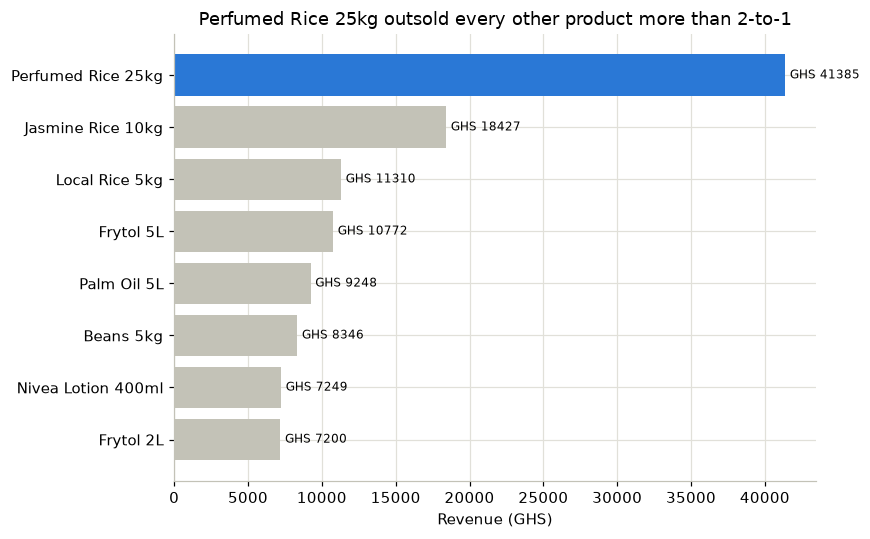

In [3]:
product_revenue = (analysis.groupby("product_name")["revenue_ghs"].sum()
                    .sort_values(ascending=True).tail(8))

fig, ax = plt.subplots(figsize=(8, 5))
colors = [PALETTE["blue"] if p == product_revenue.index[-1] else MUTED for p in product_revenue.index]
bars = ax.barh(product_revenue.index, product_revenue.values, color=colors)
ax.bar_label(bars, fmt="GHS %.0f", padding=3, fontsize=8)
ax.set_title("Perfumed Rice 25kg outsold every other product more than 2-to-1")
ax.set_xlabel("Revenue (GHS)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Note the sort: `ascending=True` with `.tail(8)` puts the **largest** value at the **top** of a horizontal bar chart, because matplotlib draws the first row at the bottom. This trips up almost everyone the first time - sorting ascending looks backwards until you remember which end of the y-axis is "first."

---

## Grouped bars: two categorical dimensions at once

A single bar chart compares one measure across one category. A **grouped bar chart** compares one measure across two categories at once - here, revenue by zone *and* channel - by clustering a small bar per channel within each zone's group. This is where categorical colour earns its place: each channel needs its own colour because a reader has to track it *across* zones, and that is identity, not magnitude.

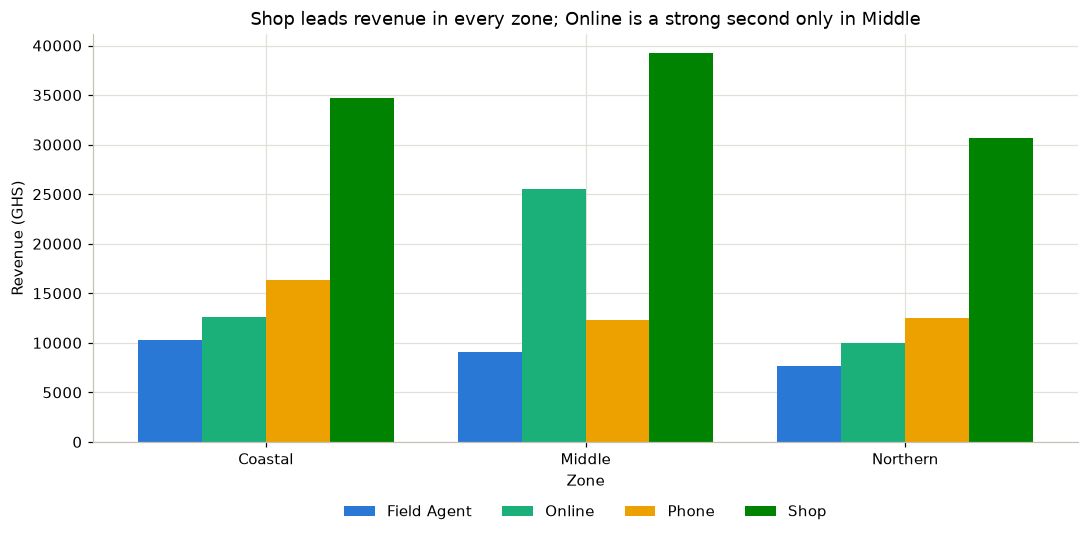

In [4]:
pivot = analysis.pivot_table(index="zone", columns="channel", values="revenue_ghs", aggfunc="sum")
zone_order = ["Coastal", "Middle", "Northern"]
channel_order = ["Field Agent", "Online", "Phone", "Shop"]
pivot = pivot.loc[zone_order, channel_order]

x = np.arange(len(zone_order))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 5))
for i, channel in enumerate(channel_order):
    ax.bar(x + (i - 1.5) * width, pivot[channel], width=width,
           label=channel, color=CHANNEL_COLOR[channel])

ax.set_xticks(x)
ax.set_xticklabels(zone_order)
ax.set_title("Shop leads revenue in every zone; Online is a strong second only in Middle")
ax.set_xlabel("Zone")
ax.set_ylabel("Revenue (GHS)")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

`x + (i - 1.5) * width` is the arithmetic that centres four bars per group around each tick: with four channels, offsets of `-1.5, -0.5, 0.5, 1.5` times the bar width spread them symmetrically. For a different number of series, the offset is `(i - (n - 1) / 2) * width`.

---

## Stacked bars: part-to-whole across categories

A stacked bar shows the same grouped data as *one* bar per zone, with channels stacked inside it - trading the ability to compare channels precisely within a zone for the ability to compare zone **totals** at a glance, which a grouped bar cannot do.

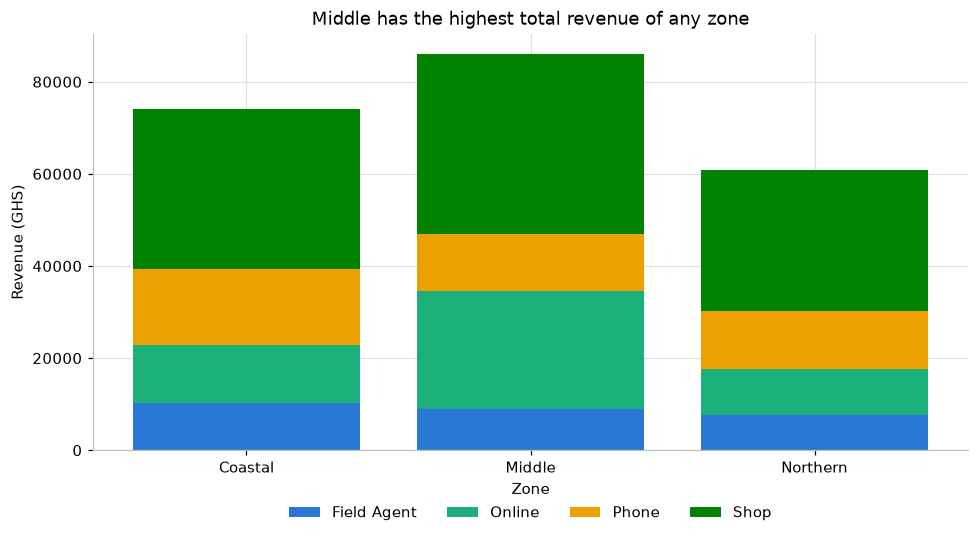

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(zone_order))
for channel in channel_order:
    values = pivot[channel].values
    ax.bar(zone_order, values, bottom=bottom, label=channel, color=CHANNEL_COLOR[channel])
    bottom += values

ax.set_title("Middle has the highest total revenue of any zone")
ax.set_xlabel("Zone")
ax.set_ylabel("Revenue (GHS)")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Resist the urge to convert this to a **100%-stacked** bar (every bar scaled to the same height, showing channel *share* instead of channel *amount*) unless the total genuinely does not matter. A 100%-stacked bar answers "what share of Northern's revenue came from Shop" - a real question - but it throws away the fact that Northern's total revenue (GHS 60,805.78) is smaller than Middle's (GHS 86,094.31). If both the shares and the totals matter, that is two charts, not one.

### Try It 2 - grouped or stacked?

Build a chart of order **count** (not revenue) by segment and channel. Decide for yourself whether a grouped or a stacked bar answers "which channel does each segment prefer" more clearly, build that one, and leave a one-line comment explaining why you chose it over the other.

In [6]:
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic21_data_visualization.ipynb)
- Previous: [21a - Anatomy of a chart](topic21a_anatomy_of_a_chart.ipynb)
- Next: [21c - Change over time](topic21c_change_over_time.ipynb)